# 5-qadam: ML prognoz modeli va qaror dvigateli

**Savol:** zonaning tuprog'i qachon chegaradan pastga tushadi va shunda nima qilish kerak?

Tizim ikki qismdan iborat:

1. **Model** (ML): hozirgi holatga qarab, sug'orilmasa namlik keyingi 1-12 soatda qancha pasayishini prognoz qiladi.
2. **Qaror dvigateli** (oddiy qoidalar): prognoz asosida sug'orish kerakmi, qancha va tasdiq kerakmi, buni **tekshirib bo'ladigan qoidalar** hal qiladi.
   Model xato qilsa ham, qoidalar belgilagan chegaradan chiqib bo'lmaydi (masalan, haddan ortiq uzoq sug'ormaslik).

Qaror qabul qiluvchi qism ataylab ML emas: ekin qaytib ekilmaydi, shuning uchun xavfsizlik chegaralari "qora quti" ga topshirilmaydi.

### Modelning g'oyasi (3 ta muhim qaror)

- **Gorizont belgi sifatida.** Bitta model "h soatdan keyin namlik qancha pasayadi" deb o'rganadi, `h` esa kirish belgisi (1..12). Shunda 12 ta alohida model o'rniga bitta model bor
  va u butun prognoz egri chizig'ini beradi. Bu orqali "namlik chegaradan **necha soatdan keyin** pastga tushadi" degan javob chiqadi.
- **Faqat sug'orishsiz oynalar bilan o'qitiladi.** Model "sug'orilmasa nima bo'ladi" savoliga javob berishi kerak, shuning uchun
  keyingi h soat ichida sug'orish bo'lgan paytlar o'qitishdan chiqarib tashlanadi.
  *Cheklov:* sug'orish odatda namlik past bo'lganda boshlanadi, shuning uchun juda quruq holatlar o'qitishda kamroq uchraydi.
- **Vaqt bo'yicha bo'lish.** Dastlabki 70% vaqt o'qitish, oxirgi 30% sinov. Tasodifiy bo'lish noto'g'ri bo'lardi, chunki qo'shni 15 daqiqalik o'lchovlar deyarli bir xil
  va model "kelajakni ko'rib" qo'yardi.

**Tayyorgarlik:** baza kamida 30 (tavsiya: 90) kunlik ma'lumot bilan to'ldirilgan bo'lishi kerak:
`python scripts/simulator.py backfill --days 90`

In [10]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sqlalchemy import create_engine

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").exists())
sys.path.insert(0, str(ROOT))

from backend.app.ml import model as M
from backend.app.ml.cleaning import clean_readings, detect_events, load_raw
from backend.app.ml.config import HORIZONS_H, TZ_OFFSET_H, ZONES
from backend.app.ml.decision import Context, decide
from backend.app.ml.features import MODEL_FEATURES, STATE_FEATURES, add_features, make_training_set
from backend.app.ml.service import build_recommendation

FOREST, SAGE, TERRA = "#1B4332", "#5C8A66", "#C97B4A"
ZONE_COLORS = {"zone_1": TERRA, "zone_2": SAGE, "zone_3": FOREST}
plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 150)
pd.set_option("display.max_colwidth", 90)

raw = load_raw(create_engine(f"sqlite:///{ROOT / 'hydromind.db'}"))
if raw.empty:
    raise SystemExit("Baza bo'sh. Avval: python scripts/simulator.py backfill --days 90")
df = add_features(clean_readings(raw))
days = (raw["timestamp"].max() - raw["timestamp"].min()).days
print(f"{len(raw)} o'lchov, {days} kun, zonalar: {sorted(raw['zone_id'].unique())}")

25920 o'lchov, 89 kun, zonalar: ['zone_1', 'zone_2', 'zone_3']


## 1. Muammo qanchalik jiddiy?

Hozirgi ("oddiy qoida") usulda sug'orish namlik chegaradan pastga tushgandan **keyin** boshlanadi. Quyida har zonada namlik qancha vaqt shartli chegaradan
(`min_moisture`) va kritik darajadan past bo'lgani. Qumloq zonada (zone_1, tez quriydi) bu eng ko'p, gil zonada (zone_3) deyarli yo'q.
Demak, muammo asosan tez quriydigan zonalarda va ayniqsa issiq kunlarda seziladi.

In [11]:
rows = []
for z, cfg in ZONES.items():
    m = df.loc[df["zone_id"] == z, "moisture"].dropna()
    rows.append({"zona": z, "chegara, %": cfg.min_moisture, "chegaradan past, % vaqt": round((m < cfg.min_moisture).mean() * 100, 1),
                 "kritik, %": cfg.critical_moisture, "kritikdan past, % vaqt": round((m < cfg.critical_moisture).mean() * 100, 1)})
pd.DataFrame(rows).set_index("zona")

,"chegara, %","chegaradan past, % vaqt","kritik, %","kritikdan past, % vaqt"
zona,,,,
zone_1,25,9.1,20,1.1
zone_2,28,3.5,23,0.0
zone_3,32,1.0,27,0.0


## 2. O'qitish jadvali

Har bir (vaqt, zona, gorizont) uchun maqsad: **namlik pasayishi** = hozirgi namlik minus h soatdan keyingi namlik (punkt). Musbat qiymat "quriyapti" degani.

O'qitish jadvali: 268,864 qator  (har bir o'lchov x 12 gorizont, sug'orishli oynalar chiqarilgan)


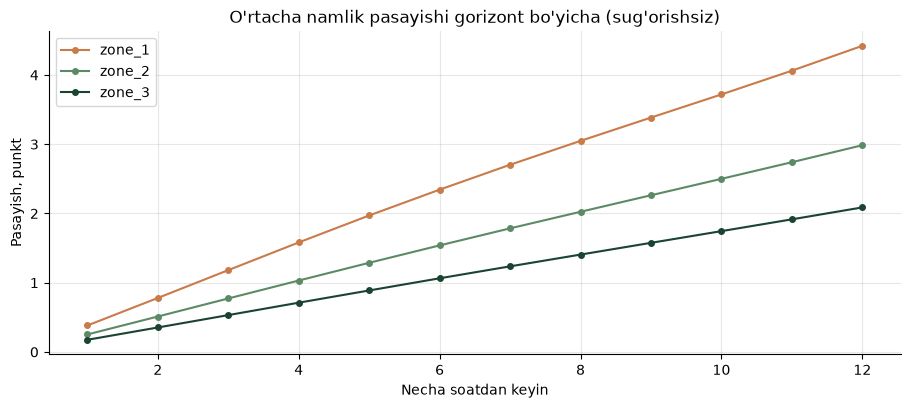

In [12]:
long = make_training_set(df, HORIZONS_H)
print(f"O'qitish jadvali: {len(long):,} qator  (har bir o'lchov x 12 gorizont, sug'orishli oynalar chiqarilgan)")

fig, ax = plt.subplots()
for z, g in long.groupby("zone_id"):
    s = g.groupby("horizon_h")["drop"].mean()
    ax.plot(s.index, s.values, color=ZONE_COLORS[z], marker="o", ms=4, label=z)
ax.set_title("O'rtacha namlik pasayishi gorizont bo'yicha (sug'orishsiz)")
ax.set_xlabel("Necha soatdan keyin")
ax.set_ylabel("Pasayish, punkt")
ax.legend()
plt.show()

## 3. O'qitish va baholash

Model (`HistGradientBoosting`) ni ikkita **oddiy usul** bilan solishtiramiz. Agar murakkab model oddiyidan yaxshi bo'lmasa, uni ishlatishning ma'nosi yo'q:

- **zona-soat o'rtachasi**: shu zona, kunning shu soati va shu gorizont uchun tarixiy o'rtacha pasayish (kunlik sikl hisobga olingan, lekin bugungi ob-havo e'tiborga olinmaydi)
- **oxirgi tezlik**: so'nggi 3 soatdagi quruyish tezligi o'zgarmay davom etadi

O'qitish: 187,894 qator,  sinov: 80,146 qator,  bo'lish chegarasi: 2026-09-16 18:34:30


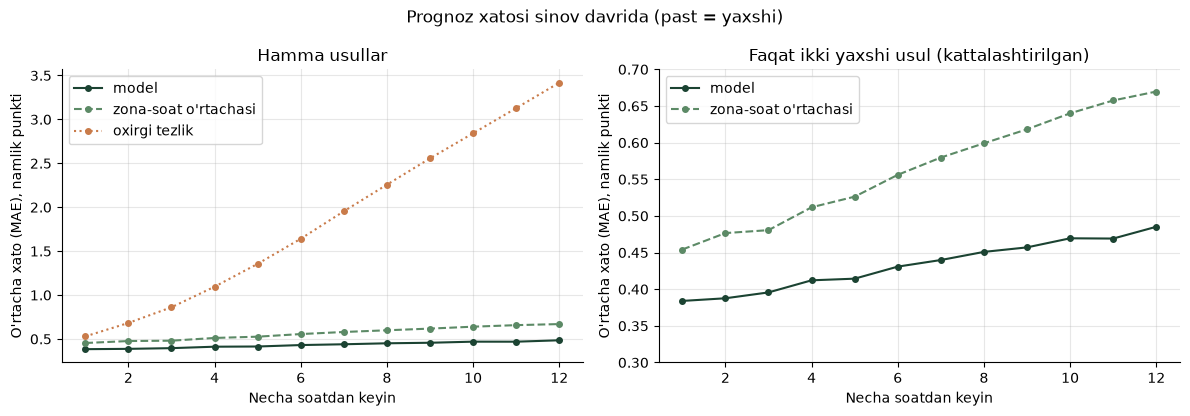

,model,zona-soat o'rtachasi,oxirgi tezlik,"model yaxshiroq (zona-soat dan), %"
horizon_h,,,,
1,0.38,0.45,0.53,15.0
3,0.40,0.48,0.86,18.0
6,0.43,0.56,1.64,23.0
12,0.49,0.67,3.42,28.0


In [13]:
ex = M.run_experiment(df)
print(f"O'qitish: {len(ex['train']):,} qator,  sinov: {len(ex['test']):,} qator,  bo'lish chegarasi: {ex['cutoff']}")

mae = ex["mae"]
styles = {"model": (FOREST, "-"), "zona-soat o'rtachasi": (SAGE, "--"), "oxirgi tezlik": (TERRA, ":")}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, cols, title in [(axes[0], list(mae.columns), "Hamma usullar"),
                        (axes[1], ["model", "zona-soat o'rtachasi"], "Faqat ikki yaxshi usul (kattalashtirilgan)")]:
    for name in cols:
        c, ls = styles[name]
        ax.plot(mae.index, mae[name], color=c, ls=ls, marker="o", ms=4, label=name)
    ax.set_title(title)
    ax.set_xlabel("Necha soatdan keyin")
    ax.set_ylabel("O'rtacha xato (MAE), namlik punkti")
    ax.legend()
axes[1].set_ylim(0.3, 0.7)
fig.suptitle("Prognoz xatosi sinov davrida (past = yaxshi)")
plt.tight_layout()
plt.show()

summary = mae.loc[[1, 3, 6, 12]].round(2)
summary["model yaxshiroq (zona-soat dan), %"] = ((1 - mae["model"] / mae["zona-soat o'rtachasi"]).loc[[1, 3, 6, 12]] * 100).round(0)
summary

**Qanday o'qiladi.** Sensor shovqini (~0,4 punkt har bir o'lchovda) tufayli ~0,4-0,5 dan past xatoga erishib bo'lmaydi, shuning uchun model bu chegaraga yaqin.
"Oxirgi tezlik" usuli esa gorizont o'sgani sari tez yomonlashadi, chunki quruyish tezligi kun davomida o'zgaradi.
Model zona-soat o'rtachasidan yaxshi, lekin farq katta emas: simulyatorda quruyishning katta qismi kunlik sikldan kelib chiqadi, model esa bugungi harorat va namlikni ham qo'shadi.
Haqiqiy dalada ob-havo o'zgaruvchanroq, shuning uchun bu farq kattaroq bo'lishi mumkin (lekin bunga kafolat yo'q, real ma'lumotda tekshirish kerak).

## 4. Qaror darajasida baholash

Xatoni punktlarda o'lchash yetarli emas. Biz uchun muhim savol: **"keyingi 12 soatda namlik chegaradan pastga tushadimi?"**
Sinov davridagi, hozir hali chegaradan yuqori bo'lgan va keyingi 12 soatda sug'orilmagan paytlarni olamiz va haqiqiy natija bilan solishtiramiz.

- *Aniqlik (precision):* "tushadi" degan ogohlantirishlarning qanchasi haqiqatan to'g'ri chiqdi
- *To'liqlik (recall):* haqiqiy tushishlarning qanchasini oldindan topdik
- *Vaqt xatosi:* chegaraga yetish vaqtini necha soatga adashdik
- *Xato zaxirasi bilan:* prognozdan modelning o'rtacha xatosi ayiriladi (pessimistik baho). Qaror dvigateli aynan shu variantni ishlatadi.

In [14]:
dec = ex["decision"].copy()
for c in ["precision", "recall", "f1"]:
    dec[c] = (dec[c] * 100).round(1)
dec["time_mae_h"] = dec["time_mae_h"].round(2)
dec[["n", "positives", "precision", "recall", "f1", "time_mae_h"]].rename(columns={
    "n": "qatorlar", "positives": "haqiqiy tushishlar", "precision": "aniqlik %", "recall": "to'liqlik %",
    "f1": "F1 %", "time_mae_h": "vaqt xatosi, soat"})

,qatorlar,haqiqiy tushishlar,aniqlik %,to'liqlik %,F1 %,"vaqt xatosi, soat"
model,5842.0,327.0,84.4,89.6,86.9,0.62
model (xato zaxirasi bilan),5842.0,327.0,74.9,96.6,84.4,0.61
zona-soat o'rtachasi,5842.0,327.0,72.3,89.3,79.9,0.76
hozirgi namlikka qarab (oldindan ko'rmaydi),5842.0,327.0,NaN,0.0,NaN,NaN


**Qanday o'qiladi.**

- Oxirgi qator hozirgi fermer usuli ("namlik chegaradan pastga tushganda sug'orish"): u **hech qachon oldindan ogohlantirmaydi**, chunki sinov qatorlarida namlik hozir chegaradan yuqori.
- Xato zaxirasi to'liqlikni oshiradi (kamroq o'tkazib yuboramiz), aniqlikni ozgina kamaytiradi (ba'zan ortiqcha ogohlantirish beramiz). Ekin uchun o'tkazib yuborish qimmatroq, shuning uchun zaxirani saqlaymiz.
- Sinov qatorlari bir-biriga bog'liq (qo'shni o'lchovlar deyarli bir xil), shuning uchun haqiqiy mustaqil hodisalar soni "qatorlar" sonidan ancha kam. Foizlarni taxminiy deb o'qing.

### Prognozlar qanday ko'rinadi

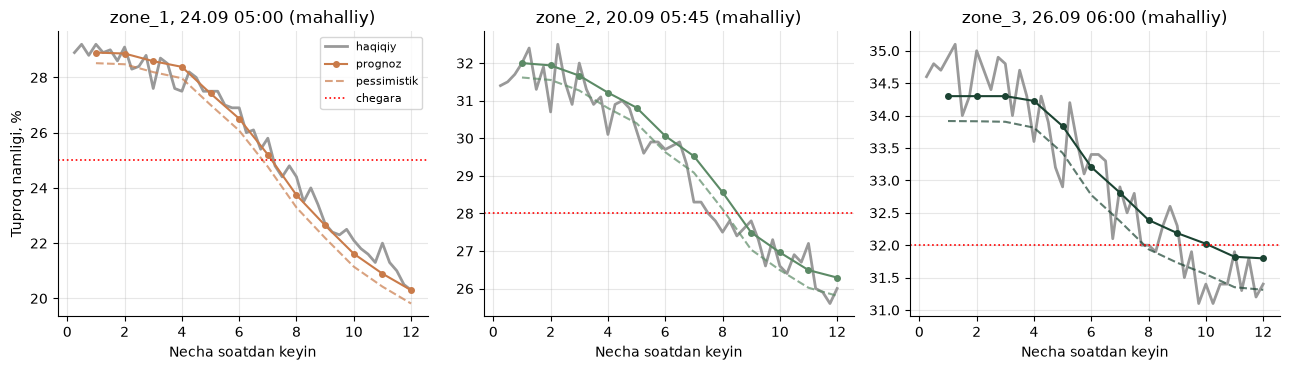

In [15]:
rows_ev, F, thr = ex["eval_rows"], ex["eval_F"], ex["eval_thr"]
fc = ex["forecaster"]
true_cross = (F < thr[:, None]).any(axis=1)
true_h = (np.argmax(F < thr[:, None], axis=1) + 1) / 4

zones = sorted(rows_ev["zone_id"].unique())
fig, axes = plt.subplots(1, len(zones), figsize=(13, 3.8), sharey=False)
axes = np.atleast_1d(axes)
for ax, z in zip(axes, zones):
    cand = np.where((rows_ev["zone_id"] == z).to_numpy() & true_cross & (np.abs(true_h - 7) < 1.5))[0]
    i = cand[len(cand) // 2] if len(cand) else np.where((rows_ev["zone_id"] == z).to_numpy())[0][0]
    m_now = rows_ev.loc[i, "moisture"]
    drops = fc.predict_drops(rows_ev.iloc[[i]])[0]
    hrs = np.array(fc.horizons)
    ax.plot(np.arange(1, F.shape[1] + 1) / 4, F[i], color="#999999", lw=2, label="haqiqiy")
    ax.plot(hrs, m_now - drops, color=ZONE_COLORS[z], marker="o", ms=4, label="prognoz")
    low = m_now - drops - np.array([fc.mae_by_h[h] for h in fc.horizons])
    ax.plot(hrs, low, color=ZONE_COLORS[z], ls="--", alpha=0.7, label="pessimistik")
    ax.axhline(thr[i], color="red", ls=":", lw=1.2, label="chegara")
    ts_local = rows_ev.loc[i, "timestamp"] + pd.Timedelta(hours=TZ_OFFSET_H)
    ax.set_title(f"{z}, {ts_local:%d.%m %H:%M} (mahalliy)")
    ax.set_xlabel("Necha soatdan keyin")
axes[0].set_ylabel("Tuproq namligi, %")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Model nimaga qaraydi? (belgilar muhimligi)

*Permutation importance*: belgi qiymatlarini aralashtirib yuborsak, xato qancha o'sadi? Qancha ko'p o'ssa, belgi shuncha muhim.

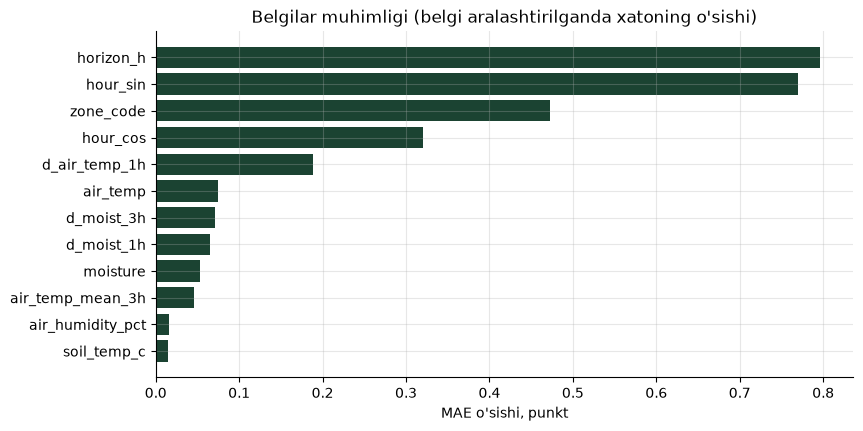

In [16]:
test = ex["test"]
sample = test.sample(min(12000, len(test)), random_state=0)
perm = permutation_importance(ex["model"], sample[MODEL_FEATURES], sample["drop"],
                              scoring="neg_mean_absolute_error", n_repeats=3, random_state=0)
imp = pd.Series(perm.importances_mean, index=MODEL_FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(imp.index, imp.values, color=FOREST)
ax.set_title("Belgilar muhimligi (belgi aralashtirilganda xatoning o'sishi)")
ax.set_xlabel("MAE o'sishi, punkt")
plt.show()

**Qanday o'qiladi.**

- `horizon_h` (qancha oldinga qaraymiz) tabiiy ravishda eng muhim, undan keyin **kun soati** (`hour_sin`, `hour_cos`), **zona** va **havo haroratining o'zgarishi** (`d_air_temp_1h`, `air_temp`). Bu bug'lanish fizikasiga mos: kunduzi va issiqda tez quriydi.
- Havo namligi, tuproq harorati va joriy namlik deyarli ahamiyatsiz.
- Joriy namlikning ahamiyatsizligi simulyator xususiyati: unda quruyish tezligi tuproq qanchalik nam ekaniga bog'liq emas. Haqiqiy tuproqda quruq tuproq sekinroq quriydi, shuning uchun real ma'lumotda `moisture` muhimroq bo'lishi kutiladi.
- Muhimligi nolga yaqin belgilar keyinchalik olib tashlanishi mumkin, lekin buni real ma'lumotda qayta tekshirgandan keyin qiling.

## 6. Qaror dvigateli: qoidalar qanday ishlaydi

Quyidagi senariylarda dvigatelga **bir xil prognoz** beriladi, farq faqat vaziyatda. Xavfsizlik qoidalari ML prognozidan ustun ekanini ko'ring.
`tasdiq (0)` avtonomlik darajasi 0 da (hammasi tasdiq bilan), `tasdiq (2)` esa 2 da (low va medium avtomatik) fermer tasdig'i kerakmi.

In [17]:
from datetime import datetime

cfg = ZONES["zone_1"]
drying = lambda start, per_h: [(h, start - per_h * h) for h in range(1, 13)]


def scenario(name, hour=18.5, m=27.0, age=5.0, fc=None, since=None, used=0.0):
    ctx = Context(now_local=datetime(2026, 10, 12, int(hour), int(round(hour % 1 * 60))), current_moisture=m, data_age_min=age,
                  forecast_low=drying(m, 0.5) if fc is None else fc, hours_since_irrigation=since, minutes_last_24h=used)
    d0, d2 = decide(cfg, ctx, autonomy=0), decide(cfg, ctx, autonomy=2)
    return {"senariy": name, "harakat": d0.action, "daqiqa": d0.minutes, "xavf": d0.risk,
            "tasdiq (0)": d0.requires_confirmation, "tasdiq (2)": d2.requires_confirmation, "asosiy sabab": d0.reasons[-1]}


table = pd.DataFrame([
    scenario("Oddiy: kechki oyna, namlik 26, tushmoqda", m=26),
    scenario("Namlik yetarli, tushmaydi", m=31, fc=[(h, 29.5) for h in range(1, 13)]),
    scenario("Tuproq to'yingan (prognoz quruq desa ham)", m=37, fc=drying(37, 3)),
    scenario("Sensor ma'lumoti 2 soat eski", age=120, m=22),
    scenario("Oyna tashqarisida (12:00), hali kritik emas", hour=12.0, m=27, fc=drying(27, 0.7)),
    scenario("Oyna tashqarisida, kritikka tez yetadi", hour=12.0, m=24, fc=drying(24, 1.5)),
    scenario("Yaqinda sug'orilgan (3 soat oldin)", m=23, fc=drying(23, 0.5), since=3.0),
    scenario("Kunlik limit deyarli tugagan (130/150 daq)", m=26, used=130),
    scenario("Prognoz yo'q (model ishlamayapti), namlik past", hour=6.0, m=22, fc=[]),
]).set_index("senariy")
table

,harakat,daqiqa,xavf,tasdiq (0),tasdiq (2),asosiy sabab
senariy,,,,,,
"Oddiy: kechki oyna, namlik 26, tushmoqda",irrigate,30,low,True,False,Hozir sug'orish oynasida (5:00-9:00 va 18:00-21:00). 30 daqiqa tavsiya etiladi (maqsad...
"Namlik yetarli, tushmaydi",wait,0,low,False,False,Keyingi 12 soatda namlik chegaradan (25%) pastga tushmaydi (eng past prognoz 29.5%).
Tuproq to'yingan (prognoz quruq desa ham),wait,0,low,False,False,Tuproq yetarli nam (37.0% >= 36%). Sug'orilmaydi.
Sensor ma'lumoti 2 soat eski,alert,0,high,False,False,Sensor ma'lumoti 120 daqiqa oldingi (ruxsat etilgan: 45). Qurilma yoki aloqani tekshir...
"Oyna tashqarisida (12:00), hali kritik emas",wait,0,low,False,False,Navbatdagi sug'orish oynasi 6.0 soatdan keyin. Shunda taxminan 30 daqiqa sug'orish rej...
"Oyna tashqarisida, kritikka tez yetadi",alert,30,high,True,True,Hozir sug'orish oynasidan tashqarida (5:00-9:00 va 18:00-21:00). Favqulodda 30 daqiqa ...
Yaqinda sug'orilgan (3 soat oldin),wait,0,low,False,False,Oxirgi sug'orishdan beri 3.0 soat o'tgan (minimal oraliq 10 soat).
Kunlik limit deyarli tugagan (130/150 daq),irrigate,15,medium,True,False,Davomiylik chegaralar tufayli qisqartirildi (kerak edi: 30 daqiqa).
"Prognoz yo'q (model ishlamayapti), namlik past",irrigate,45,medium,True,False,Hozir sug'orish oynasida (5:00-9:00 va 18:00-21:00). 45 daqiqa tavsiya etiladi (maqsad...


## 7. O'tmishni qayta o'ynash (replay)

Dvigatel o'tgan kunlarda, **faqat o'sha paytgacha mavjud bo'lgan ma'lumot bilan** qanday qaror chiqargan bo'lardi? Sinov davridagi oxirgi kunlar uchun,
har kuni 06:00, 12:00 va 18:00 (mahalliy vaqt). Bu aynan API (`/zones/{zone_id}/recommendation`) ishlatadigan funksiya.

In [18]:
zone = "zone_1"
zc = ZONES[zone]
zraw = raw[raw["zone_id"] == zone]
zevents = detect_events(df)
zevents = zevents[zevents["zone_id"] == zone]

last_ts = zraw["timestamp"].max()
out = []
for day in pd.date_range((last_ts - pd.Timedelta(days=3)).normalize(), last_ts.normalize(), freq="D"):
    for local_h in (6, 12, 18):
        T = day + pd.Timedelta(hours=local_h - TZ_OFFSET_H)
        if T > last_ts or T < ex["cutoff"]:
            continue
        window = zraw[(zraw["timestamp"] > T - pd.Timedelta(hours=48)) & (zraw["timestamp"] <= T)]
        r = build_recommendation(window, zc, T, fc, autonomy=0)
        started = zevents[(zevents["start"] > T) & (zevents["start"] <= T + pd.Timedelta(hours=3))]
        out.append({"mahalliy vaqt": f"{(T + pd.Timedelta(hours=TZ_OFFSET_H)):%d.%m %H:%M}", "namlik": r["current_moisture"],
                    "harakat": r["action"], "daqiqa": r["minutes"], "xavf": r["risk"],
                    "chegaragacha, soat": r["hours_to_threshold"],
                    "fermer (simulyatsiya) keyingi 3 soatda sug'organmi": len(started) > 0,
                    "sabab": r["reasons"][0][:70]})
pd.DataFrame(out).set_index("mahalliy vaqt")

,namlik,harakat,daqiqa,xavf,"chegaragacha, soat",fermer (simulyatsiya) keyingi 3 soatda sug'organmi,sabab
mahalliy vaqt,,,,,,,
10.10 06:00,37.6,wait,0,low,NaN,False,Tuproq yetarli nam (37.6% >= 36%). Sug'orilmaydi.
10.10 12:00,34.7,wait,0,low,NaN,False,Keyingi 12 soatda namlik chegaradan (25%) pastga tushmaydi (eng past p
10.10 18:00,30.0,wait,0,low,NaN,False,Keyingi 12 soatda namlik chegaradan (25%) pastga tushmaydi (eng past p
11.10 06:00,29.1,irrigate,15,low,7.0,False,Namlik ~7 soatdan keyin chegaradan (25%) pastga tushishi kutilmoqda.
11.10 12:00,27.5,wait,0,low,2.0,False,Namlik ~2 soatdan keyin chegaradan (25%) pastga tushishi kutilmoqda.
11.10 18:00,23.0,irrigate,45,medium,0.0,True,Namlik chegaradan past (23.0% < 25%).
12.10 06:00,32.4,wait,0,low,NaN,False,Keyingi 12 soatda namlik chegaradan (25%) pastga tushmaydi (eng past p
12.10 12:00,30.3,wait,0,low,NaN,False,Keyingi 12 soatda namlik chegaradan (25%) pastga tushmaydi (eng past p
12.10 18:00,26.9,wait,0,low,NaN,True,Keyingi 12 soatda namlik chegaradan (25%) pastga tushmaydi (eng past p


**Qanday o'qiladi.**

- Dvigatel kunduzi quruyish prognoz qilsa ham, sug'orishni oyna ochilguncha kutadi (xavfsizlik qoidasi) va oynada tavsiya beradi.
- Pasayishni **oldindan** ko'radi: masalan, ertalab namlik hali chegaradan yuqori bo'lsa ham, ~7 soatdan keyin tushishi kutilsa, oynada qisqa sug'orish tavsiya qiladi.
- Oxirgi ustun simulyatsiyadagi "fermer" nima qilganini ko'rsatadi. U **to'g'ri javob emas**: simulyatordagi fermer ba'zan tasodifiy ravishda chegaradan oldinroq
  (masalan, 28% da, chegara 25% bo'lsa ham) sug'orishni boshlaydi. Bunday paytlarda dvigatel qoidasi bo'yicha kutadi, chunki namlik chegaradan yuqori va 12 soatda tushmaydi.
- Bu qayta o'ynash qaror qanday chiqishini ko'rsatadi, lekin "tavsiya bajarilganda natija yaxshiroq bo'lardi" degani emas: buni faqat haqiqiy pilotda tekshirish mumkin.

## Xulosa va keyingi qadam

- Model oddiy usullardan yaxshi, ammo asosiy qiymat prognozning o'zidan ko'ra **oldindan ogohlantirish** va **qoidalar bilan cheklangan qaror**dir.
- Eng muhim cheklov: hammasi simulyatorda sinalgan. Haqiqiy sensor ma'lumoti (shovqin, tuproq xususiyatlari, ob-havo) bilan natija pastroq bo'ladi, shuning uchun pilotda **tavsiya rejimida** (tasdiq bilan) boshlash kerak.
- `backend/app/ml/config.py` dagi chegaralar (min, kritik, maqsad) ML emas, agronom/fermer bilan kelishilishi kerak bo'lgan qiymatlar.

**6-qadam:** dashboard (grafiklar va tavsiyalar bir joyda), keyin **7-qadam:** Telegram bot orqali fermer tasdig'i.